# 3. Why do algotypes cluster?

We compare mixed bubble/insertion/selection cells with two controls: shuffled labels on the **same trajectories**, and a bubble-only array carrying arbitrary labels. Labels move with stable identities and never enter a sorting decision.

Our measure is the fraction of equal-label adjacent pairs. It differs from the paper's cell-based aggregation measure, so the numerical values should not be compared directly.

In [1]:
%matplotlib inline
from pathlib import Path
import tempfile
import matplotlib.pyplot as plt
from cell_research.experiment import Config, run, replay
Path("outputs").mkdir(exist_ok=True)
output = Path(tempfile.mkdtemp(prefix="clustering-", dir="outputs"))

## Chance depends on label counts

With label counts n_k among n cells, the exact shuffle expectation is sum[n_k(n_k-1)]/[n(n-1)]. It is generally not exactly 1 divided by the number of types in finite arrays.

In [2]:
from cell_research.metrics import aggregation, shuffled_baseline
labels = ["bubble"] * 6 + ["insertion"] * 6 + ["selection"] * 6
print("Clustered arrangement:", aggregation(labels))
print("Uniform shuffle expectation:", shuffled_baseline(labels))

Clustered arrangement: 0.8823529411764706
Uniform shuffle expectation: 0.29411764705882354


## Controlled runs across two schedulers

Run 20 independently seeded trials of 18 cells for both random and round-robin scheduling. The controls are paired within trials; label counts and initial arrays are preserved. Each trajectory is aligned by its fraction of observed successful swaps, not elapsed time. Every terminal outcome is saved.

Shading shows pointwise 95% bootstrap intervals over trials (2,000 resamples). These are not simultaneous bands. Summary contrasts use a paired bootstrap of the average difference across the trajectory, not its peak.

{'scheduler': 'random', 'contrast': 'mixed - shuffled_labels', 'trials': 20, 'mean_difference': 0.024113570180547474, 'ci95_low': -0.02840738934187536, 'ci95_high': 0.07572620122306342}
{'scheduler': 'random', 'contrast': 'mixed - single_policy', 'trials': 20, 'mean_difference': 0.030997670355270828, 'ci95_low': 0.002294241409435064, 'ci95_high': 0.06000224956319161}
{'scheduler': 'round_robin', 'contrast': 'mixed - shuffled_labels', 'trials': 20, 'mean_difference': 0.01907542224810716, 'ci95_low': -0.029731937973209086, 'ci95_high': 0.06470425888177049}
{'scheduler': 'round_robin', 'contrast': 'mixed - single_policy', 'trials': 20, 'mean_difference': 0.03578800232964473, 'ci95_low': 0.012088257134536977, 'ci95_high': 0.05996983838089691}


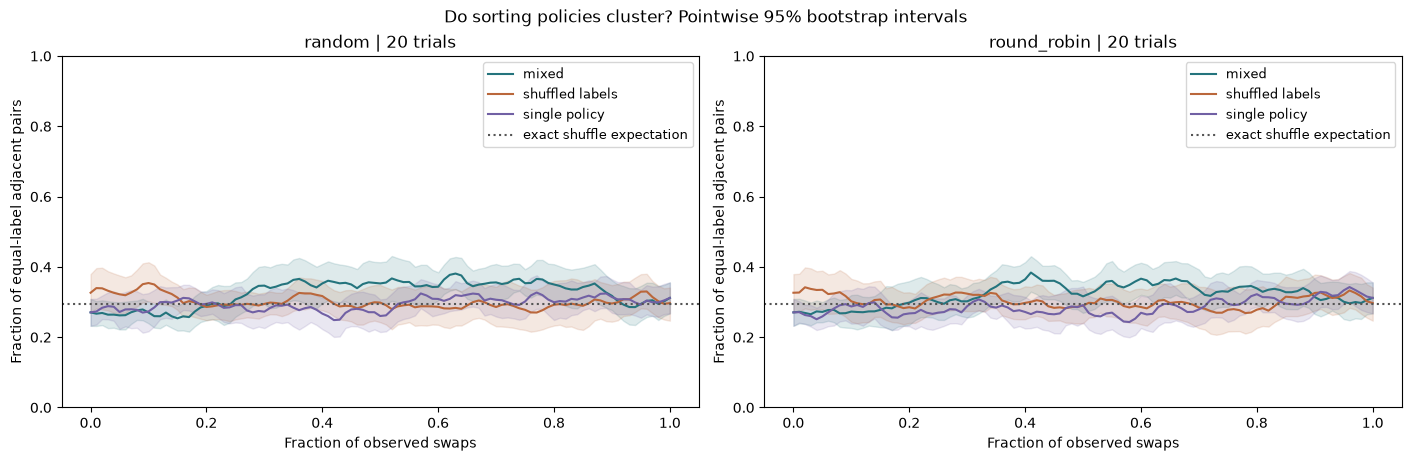

In [3]:
from cell_research.studies import clustering_study
study = clustering_study(output / "study", trials=20, n=18, seed=29)
for row in study["summary"]:
    print(row)
plt.show()

## Check the underlying runs

An attractive mean curve can conceal nonconvergent runs. Count stopping reasons before interpreting clustering. Saved label mappings and event logs let us inspect individual examples.

In [4]:
from collections import Counter
print(Counter((row["scheduler"], row["condition"], row["termination"]) for row in study["rows"]))
recording = output / "study" / "random-trial-000-mixed"
result = replay(recording)
print("Example replay:", result.termination, result.final_values)
print("Recordings, labels, CSV summaries, and curves:", output)

Counter({('random', 'mixed', 'sorted'): 20, ('random', 'single_policy', 'sorted'): 20, ('round_robin', 'mixed', 'sorted'): 20, ('round_robin', 'single_policy', 'sorted'): 20})
Example replay: sorted [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Recordings, labels, CSV summaries, and curves: /Users/mhough/Workspace/cell_research/outputs/clustering-h49ye6oz


## Explore and interpret

Increase the trial count and array size; add `"threaded"` to the `schedulers` argument. Compare two policies rather than three by adapting the study setup. Examine raw activations as another time coordinate, and ask whether unequal policy speeds could account for a transient cluster.

Evidence of clustering is a statement about trajectories. Whether it merits words such as preference, agency, or freedom is an additional interpretation. Neither positive nor null clustering establishes a metaphysical conclusion.

Sources: [sorting study](https://arxiv.org/abs/2401.05375), [Ingressing Minds](https://www.mdpi.com/2409-9287/11/5/161), [fork methods](../docs/methods.md).